In [1]:
#Problem Statement - In the challenge 3, how a quantum circuit can produce correlated outcomes is 
#investigated. Now, design a circuit that switches between correlated and opposite measurement outcomes. 
#Your goal is to create two different two-qubit behaviors using only a small number of quantum gates.

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

Circuit A: Correlated Outcomes


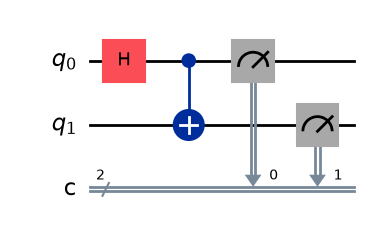

In [3]:
qc_a = QuantumCircuit(2, 2)

qc_a.h(0)             # Create superposition on qubit 0
qc_a.cx(0, 1)         # Apply CNOT: qubit 0 controls qubit 1
qc_a.measure([0, 1], [0, 1])

print("Circuit A: Correlated Outcomes")
display(qc_a.draw("mpl"))

Circuit B: Opposite Outcomes


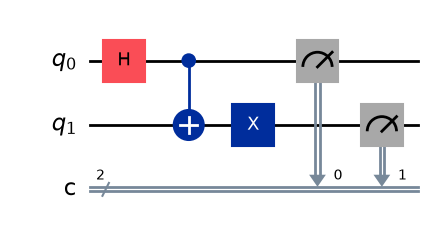

In [4]:
qc_b = QuantumCircuit(2, 2)

qc_b.h(0)             # Create superposition on qubit 0
qc_b.cx(0, 1)         # Correlate the two qubits
qc_b.x(1)             # Flip qubit 1
qc_b.measure([0, 1], [0, 1])

print("Circuit B: Opposite Outcomes")
display(qc_b.draw("mpl"))

In [5]:
simulator = AerSimulator()

result = simulator.run(
    [qc_a, qc_b],
    shots=100
).result()

counts_a = result.get_counts(0)
counts_b = result.get_counts(1)

print("Part A measurement results:", counts_a)
print("Part B measurement results:", counts_b)


Part A measurement results: {'00': 52, '11': 48}
Part B measurement results: {'01': 55, '10': 45}


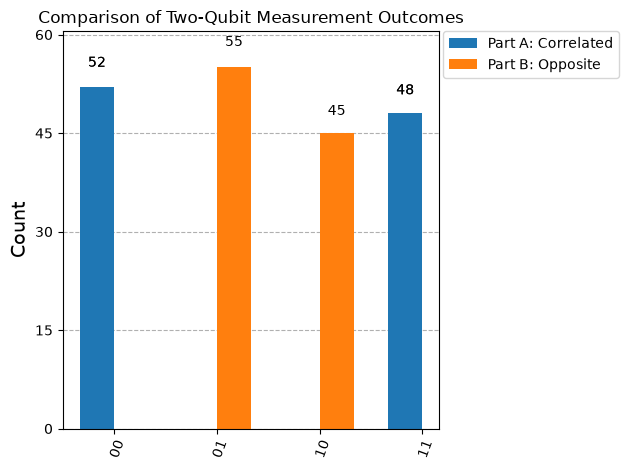

In [6]:
fig = plot_histogram(
    [counts_a, counts_b],
    legend=["Part A: Correlated", "Part B: Opposite"],
    title="Comparison of Two-Qubit Measurement Outcomes"
)

display(fig)


In [7]:
#1.Which outcomes are dominant in Part A?
#The dominant outcomes are 00 and 11. Both qubits have the same measurement value.

In [ ]:
#@2. Which outcomes are dominant in Part B?
#The dominant outcomes are 01 and 10. The two qubits have opposite measurement values.

In [8]:
#3. What changed between the two circuits?
#An X gate was added to qubit 1 after the CNOT gate in Part B.

In [9]:
#4. Why did the measurement relationship change?
#The X gate flips qubit 1 from 0 to 1 or from 1 to 0. This changes the correlated state into an opposite-outcome state while preserving the equal probabilities of the two possible results.

In [ ]:
#5. Will all four outcomes appear?
#No, not in these ideal simulations. Part A produces only 00 and 11, while Part B produces only 01 and 10. Additional outcomes may appear on noisy quantum hardware.

In [ ]:
#The experiment demonstrates how quantum gates control the relationship between measurement outcomes. 
#The H and CNOT gates create a correlated two-qubit state. Adding an X gate to the second qubit changes the 
#correlation into opposite outcomes. Histograms make these differences visible.